# WP13 FINAL DEMO v1

Gerçek kayıtlar, ayrı tahmin/açıklama/PDF kolları. Yeni model/API/attribution yok. İnsan PENDING; kaynak güncelliği doğrulanmadı.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP13/final_demo_v1';F=ROOT/'reports/figures/WP13/final_demo_v1'
display(pd.read_csv(Q/'coverage.csv'))


,parent,outer_fold,PT_scores,graph_example_PTs,B1_SHAP_example_PTs,new_inference
0,DB00199,3,318,2,2,False
1,DB00254,1,240,2,2,False


**Yorum:** Kendi-fold tahminleri PDF olmadan kullanılabilir. Açıklama kapsamı tüm PT uzayından daha dardır; olmayan açıklama doldurulmaz.

,class_id,score_observed_record_proxy,model_job_key,target_name
0,C0042963,0.932433,primary_o03_final_A1P1,Vomiting
1,C0015230,0.926896,primary_o03_final_A1P1,Rash
2,C0011991,0.922435,primary_o03_final_A1P1,Diarrhoea
3,C0011603,0.920268,primary_o03_final_A1P1,Dermatitis
4,C0002792,0.906503,primary_o03_final_A1P1,Anaphylactic shock
5,C0040034,0.903854,primary_o03_final_A1P1,Thrombocytopenia
6,C0020517,0.901444,primary_o03_final_A1P1,Hypersensitivity
7,C0033774,0.876964,primary_o03_final_A1P1,Pruritus
8,C0018681,0.840329,primary_o03_final_A1P1,Headache
9,C0042109,0.839565,primary_o03_final_A1P1,Urticaria


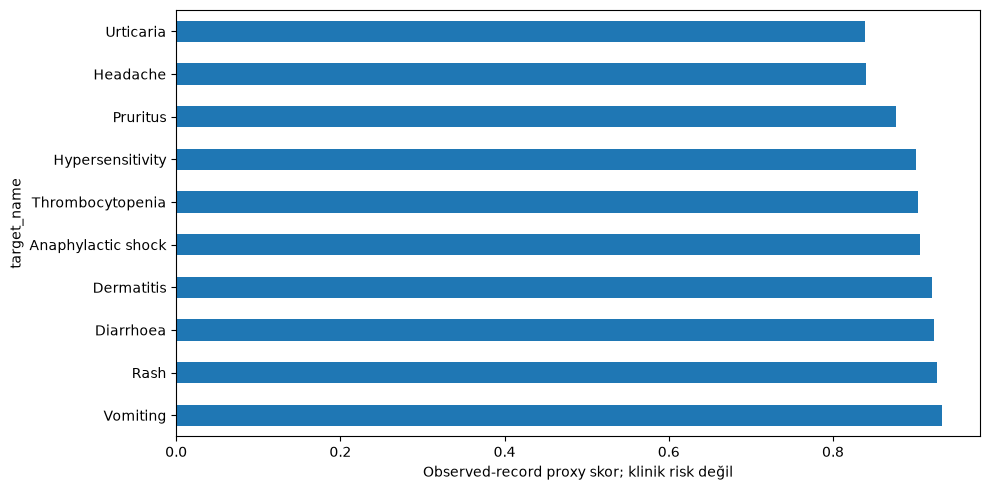

In [2]:
b=json.loads((Q/'DB00199.json').read_text(encoding='utf-8'))
p=pd.DataFrame(b['predictions']);display(p.head(10))
fig,ax=plt.subplots(figsize=(10,5));p.head(10).plot.barh(x='target_name',y='score_observed_record_proxy',ax=ax,legend=False);ax.set_xlabel('Observed-record proxy skor; klinik risk değil');plt.tight_layout();plt.savefig(F/'05_actual_recorded_ranking.png',dpi=160);plt.show()

**Yorum:** İlk10 frozen sıralama görselidir; yeni tahmin veya doğruluk değerlendirmesi değildir.

In [3]:
g=pd.DataFrame(b['graph']);s=pd.DataFrame(b['shap']);display(g[g.class_id.eq('C0000731')].head(12));display(s[s.class_id.eq('C0000731')]);display(pd.read_csv(Q/'DB00199_reference_UNMAPPED.csv').head(8))

,context,protocol,outer_fold,drug_id,class_id,mode,role,protein_id,protein_a,protein_b,original_logit,intervened_logit,delta_z,status,kind
0,primary_o03_final,primary,3,DB00199,C0000731,fixed,target,O43193,NaN,NaN,-1.768257,-1.316162,-0.452095,OK,role
2,primary_o03_final,primary,3,DB00199,C0000731,delete,target,O43193,NaN,NaN,-1.768257,-1.620388,-0.147869,OK,role
4,primary_o03_final,primary,3,DB00199,C0000731,fixed,target,Q12809,NaN,NaN,-1.768257,-1.464032,-0.304226,OK,role
6,primary_o03_final,primary,3,DB00199,C0000731,delete,target,Q12809,NaN,NaN,-1.768257,-1.916127,0.147869,OK,role
8,primary_o03_final,primary,3,DB00199,C0000731,fixed,enzyme,P08684,NaN,NaN,-1.768257,-1.704037,-0.064220,OK,role
10,primary_o03_final,primary,3,DB00199,C0000731,delete,enzyme,P08684,NaN,NaN,-1.768257,-1.767135,-0.001123,OK,role
12,primary_o03_final,primary,3,DB00199,C0000731,fixed,enzyme,P20815,NaN,NaN,-1.768257,-1.696893,-0.071364,OK,role
14,primary_o03_final,primary,3,DB00199,C0000731,delete,enzyme,P20815,NaN,NaN,-1.768257,-1.756420,-0.011838,OK,role
16,primary_o03_final,primary,3,DB00199,C0000731,fixed,enzyme,P24462,NaN,NaN,-1.768257,-1.713426,-0.054832,OK,role
18,primary_o03_final,primary,3,DB00199,C0000731,delete,enzyme,P24462,NaN,NaN,-1.768257,-1.781218,0.012961,OK,role


,context,protocol,outer_fold,drug_id,class_id,feature,feature_type,standardized_value,raw_value,background_mean_standardized,coefficient,SHAP_logit,selection,term
0,primary_o03_final,primary,3,DB00199,C0000731,chem__MW,chemistry,1.430119,733.9370,5.163828e-17,0.169495,0.242398,lexicographic only;train vocabulary and input availability;no test outcomes,Abdominal distension
1,primary_o03_final,primary,3,DB00199,C0000731,chem__LogP,chemistry,0.689285,1.7856,1.613696e-18,0.521407,0.359398,lexicographic only;train vocabulary and input availability;no test outcomes,Abdominal distension
2,primary_o03_final,primary,3,DB00199,C0000731,chem__HBD,chemistry,0.288117,5.0000,-2.840105e-17,0.099200,0.028581,lexicographic only;train vocabulary and input availability;no test outcomes,Abdominal distension
3,primary_o03_final,primary,3,DB00199,C0000731,chem__HBA,chemistry,1.276998,14.0000,-1.600787e-16,0.061311,0.078294,lexicographic only;train vocabulary and input availability;no test outcomes,Abdominal distension
4,primary_o03_final,primary,3,DB00199,C0000731,chem__TPSA,chemistry,0.472751,193.9100,-1.213500e-16,-0.251116,-0.118715,lexicographic only;train vocabulary and input availability;no test outcomes,Abdominal distension
5,primary_o03_final,primary,3,DB00199,C0000731,mask__chemistry,availability_mask,1.000000,1.0000,1.000000e+00,-0.726738,0.000000,lexicographic only;train vocabulary and input availability;no test outcomes,Abdominal distension


,candidate_id,Türkçe kaynak terimi,Sayfa,Kapsam,PT eşlemesi,İnsan kararı
0,trcandidate:6a658ec1b20191870f6eb26ca689774f49b6627fdc06f70827bbb1df0e5a77c9,Nefes darlığı,6,product_specific,UNMAPPED,PENDING
1,trcandidate:a317b22a7cd8ea5d8f06a9c7591136d3c30fa2986bbb257367c81ec3802cfd7d,Baygınlık,6,product_specific,UNMAPPED,PENDING
2,trcandidate:3a1a219150813d15bae146a323f992beaed508293d98118f3538fd1c21d42ce5,"Yüz, dudaklar ya da boğazda şişme",6,product_specific,UNMAPPED,PENDING
3,trcandidate:c038267244250ad751dfaabae710f67124b06c6720420073992e576d5f028958,Deri döküntüleri,6,product_specific,UNMAPPED,PENDING
4,trcandidate:b3977ee8ae6cf75553de52558cc48752b3b544eeba74b9901e4a731a47f88820,Ülser ve yara gibi büyük akışkan kabarcıkları kapsayan şiddetli deri reaksiyonları,6,product_specific,UNMAPPED,PENDING
5,trcandidate:9abf82bc6213c935554af58600e48229483c4579bb5a4960ee0d959a5f9bb05c,Ağız ve boğazda ülser,6,product_specific,UNMAPPED,PENDING
6,trcandidate:2734ea9fff5788254a97b57ed19190d501594f952025bd5dcbbefe6baa4edc33,Şiddetli ya da uzun süreli kanlı ya da sümüksü ishal,7,product_specific,UNMAPPED,PENDING
7,trcandidate:3a92b053629fed28c85dd83787264606327a3af02be47ce636b5c7d2f02da367,Hasta hissetme veya hasta olma,7,product_specific,UNMAPPED,PENDING


**Yorum:** Δz A1P1 mesaj müdahalesidir; SHAP B1 logit açıklamasıdır. Kaynak terimleri UNMAPPED; otomatik PT eşlemesi veya negatif üretimi yok.

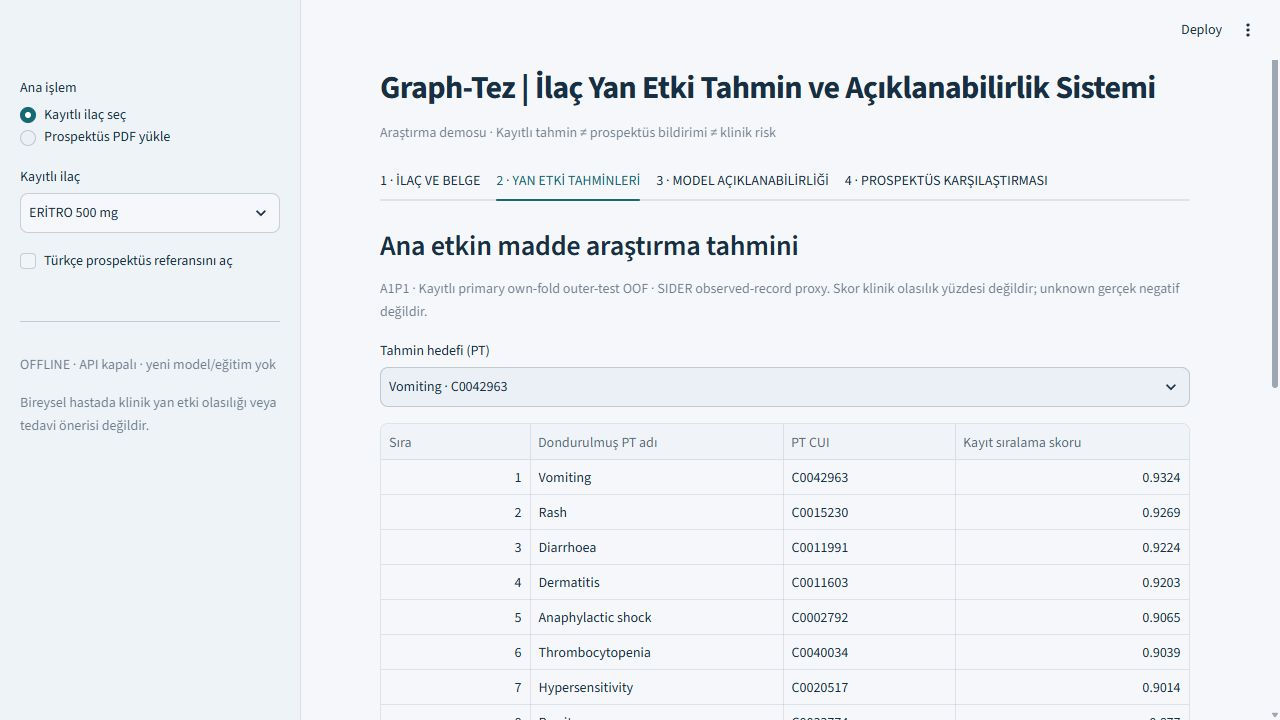

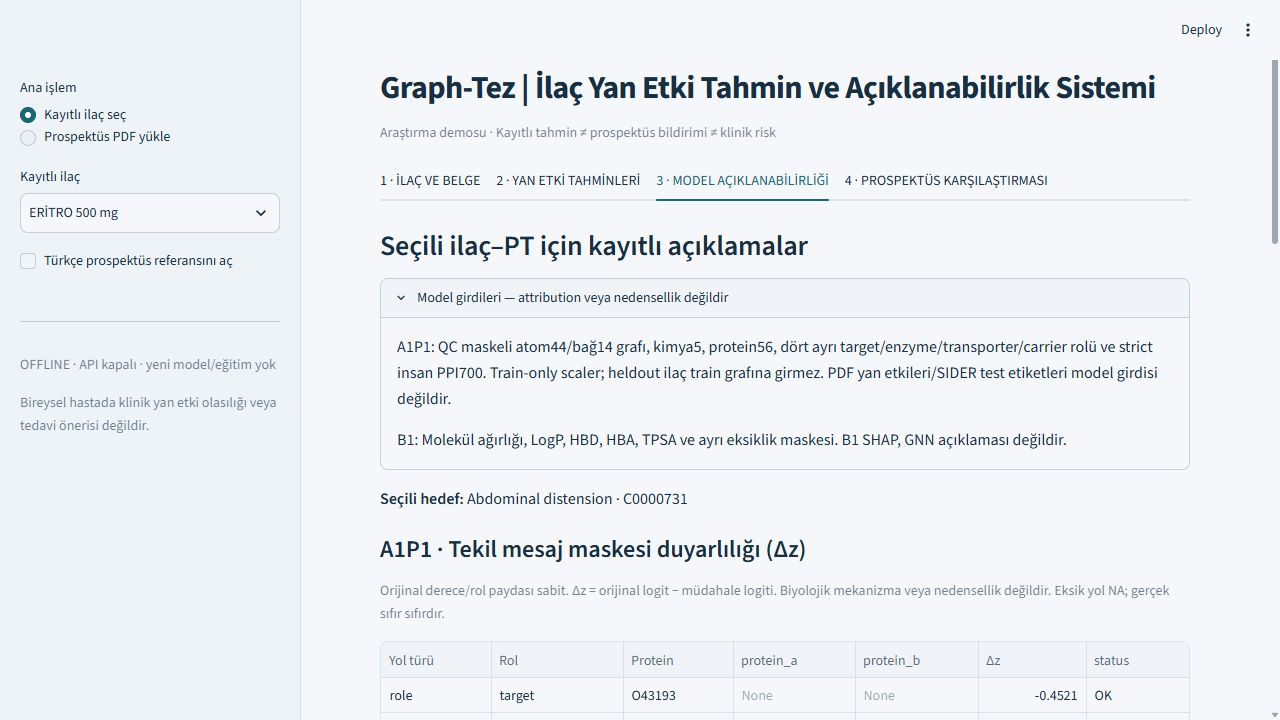

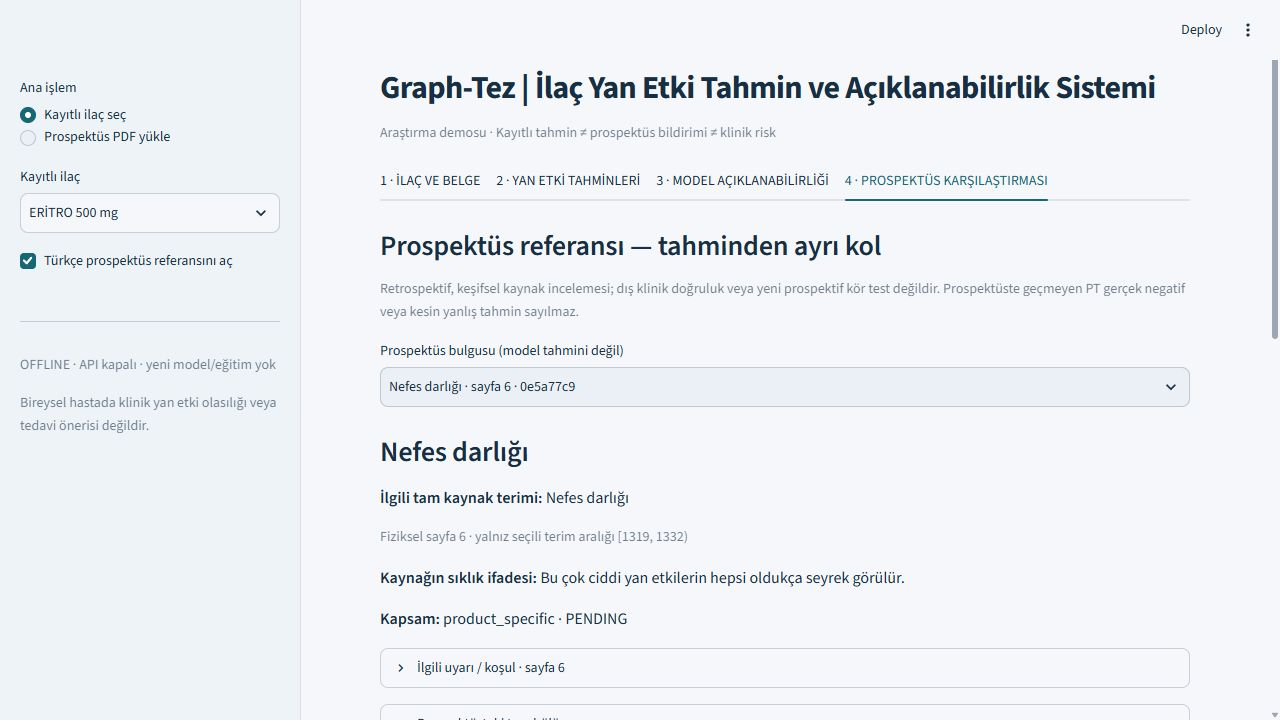

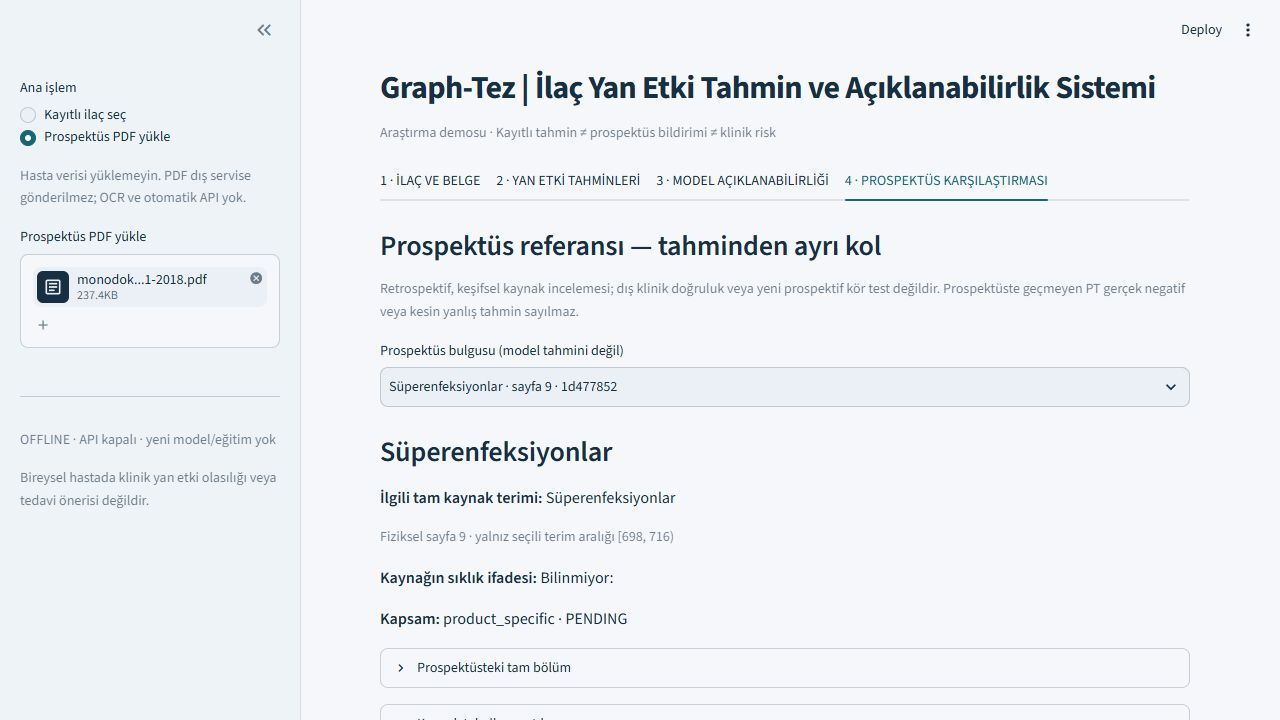

In [4]:
from IPython.display import Image
for f in ['01_real_OOF_without_PDF.jpg','02_real_A1P1_intervention.jpg','03_selected_term_not_six_predictions.jpg','04_real_PDF_upload.jpg']:display(Image(filename=str(F/f),width=1000))

**Yorum:** Ekranlar gerçeklocalhost8508 arayüzündendir. Gerçek MONODOKS dosyası yüklendi; metin çıktısı değil ham PDF kullanıldı. Sunum başarısı klinik/semantik onay değildir.